# 05 · Dashboard: from engine tables to a report finance can work from

Days 1–4 built and validated the engine. Finance doesn't want 600 rows of SQL output, though; at close they need to see in a minute **does it tie, what's broken, who owns it, and how old is it**.

Design choices, the same ones I'd make in Power BI:

- **A thin semantic layer** (`dashboard/marts.sql`): six small pre-aggregated tables on top of the engine. The page only reads marts, so every visual can be traced to one SQL query, and the same CSVs (`data/output/dashboard/`) can be loaded straight into Power BI.
- **Tie-out before publish**: `src/dashboard.py` checks each mart back to the engine and refuses to write the page if any check fails.
- **Four pages**: Overview (does it tie), Exceptions (slicers + work queue), Gateway fees (the claim), Settlements (cash in the bank).
- **One self-contained HTML file** so it opens anywhere without a server or licence.

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import dashboard as dash

pd.set_option("display.width", 170); pd.set_option("display.max_colwidth", 80)
marts, ties = dash.load()
for name, ok in ties:
    print(f"[{'PASS' if ok else 'FAIL'}] {name}")
assert all(ok for _, ok in ties)

[PASS] daily status keys = leg-1 keys (excl. no-action)
[PASS] daily break value = leg-1 break value
[PASS] owner queue items and ₹ = exception register
[PASS] fee excess = fee claims in the register
[PASS] settlement tracker covers every payout once
[PASS] bridge start − bank credits = sum of bridge steps
[PASS] unexplained residual is ₹0.00


## 1 · The semantic layer

Each mart answers one question. The window functions do the work that would otherwise be DAX measures:

| Mart | Question | SQL technique |
|---|---|---|
| `dash_daily_status` | Is the match rate stable through the month? | `FILTER` aggregates, 7-day trailing `SUM() OVER (ROWS 6 PRECEDING)` |
| `dash_owner_queue` | Who owns what, and how old is it? | `CASE` ageing buckets, `GROUP BY ALL` |
| `dash_fee_daily` | Is the gateway charging the contract rate? | ratio of sums per day, running `SUM() OVER (PARTITION BY method)` |
| `dash_settlements` | Did every payout reach the bank on time? | due-date vs bank-date status |
| `dash_method_breaks` | Is one payment method the problem? | break rate per method |
| `dash_kpis` | The headline cards | scalar sub-queries over the marts |

In [2]:
print((ROOT / "dashboard" / "marts.sql").read_text()[:1900])

-- Dashboard marts: small, pre-aggregated tables the dashboard reads.
-- Runs on top of the engine tables (sql/00-60). Every figure on the dashboard comes from one of
-- these, and src/dashboard.py checks that each mart ties back to the engine before writing HTML.

-- Close date for ageing: the last day of the period (IST).
CREATE OR REPLACE TABLE dash_params AS
SELECT (period_end - INTERVAL 1 DAY)::DATE AS close_date FROM params;

-- 1 · Leg-1 status per IST day: what auto-matched, what is timing, what is a break.
CREATE OR REPLACE TABLE dash_daily_status AS
WITH m AS (
    SELECT COALESCE(l.posting_ts_ist, l.gw_ts_ist)::DATE AS day_ist, c.outcome, l.value_inr
    FROM leg1_match l JOIN rule_catalogue c USING (rule)
    WHERE c.outcome <> 'no_action'
)
SELECT day_ist,
       COUNT(*)                                        AS keys,
       COUNT(*) FILTER (WHERE outcome = 'matched')     AS matched_keys,
       COUNT(*) FILTER (WHERE outcome = 'timing')      AS timing_keys,
       COUNT(

In [3]:
k = marts["dash_kpis"].T.rename(columns={0: "value"})
k["value"] = [f"{v:.4%}" if n.endswith("rate") else f"{v:,.2f}" if n.endswith("inr") else f"{v:,.0f}"
              for n, v in zip(k.index, k["value"])]
k

,value
erp_net_sales_inr,"21,991,231.50"
bank_credits_inr,"20,449,800.31"
unexplained_inr,0.00
auto_match_rate,98.0480%
leg1_keys,"23,976"
open_items,619
break_items,485
break_inr,"994,350.18"
timing_inr,"790,356.60"
claim_inr,"3,953.16"


## 2 · Is the match rate stable through the month?

A month-level 98% can hide a bad week. The 7-day trailing break rate shows whether breaks cluster (an outage, a bad deploy) or are spread evenly (process).

In [4]:
d = marts["dash_daily_status"]
print(f"{len(d)} IST days; daily auto-match rate {d.auto_match_rate.min():.2%} – {d.auto_match_rate.max():.2%}")
full = d[(d.timing_keys == 0)]
print(f"days with no cut-off rows: {len(full)}; auto-match {full.auto_match_rate.min():.2%} – {full.auto_match_rate.max():.2%}, "
      f"7-day break rate {d.break_rate_7d.iloc[6:].min():.2%} – {d.break_rate_7d.iloc[6:].max():.2%}")
d.head(8)

32 IST days; daily auto-match rate 0.00% – 99.22%
days with no cut-off rows: 30; auto-match 97.67% – 99.22%, 7-day break rate 1.33% – 1.60%


,day_ist,keys,matched_keys,timing_keys,break_keys,break_inr,auto_match_rate,break_rate_7d
0,2026-10-01,790,720,62,8,7501.0,0.911392,0.010127
1,2026-10-02,743,736,0,7,5704.0,0.990579,0.009785
2,2026-10-03,771,753,0,18,16042.0,0.976654,0.014323
3,2026-10-04,774,757,0,17,17195.0,0.978036,0.016244
4,2026-10-05,813,801,0,12,11810.0,0.985240,0.015934
5,2026-10-06,772,766,0,6,5673.0,0.992228,0.014583
6,2026-10-07,770,759,0,11,8415.0,0.985714,0.014541
7,2026-10-08,756,746,0,10,9010.0,0.986772,0.015003


The days below the range are the two month edges, where cut-off rows sit in *timing*. Inside the month, the break rate stays in a narrow band with no spike, which agrees with Day 2's finding that breaks come from process rather than one incident.

## 3 · Who owns what, and how old is it?

In [5]:
q = marts["dash_owner_queue"]
pv = q.pivot_table(index="owner", columns="age_bucket", values="items", aggfunc="sum", fill_value=0)
pv = pv.reindex(columns=[c for c in dash.AGE_ORDER if c in pv.columns])
pv["total items"] = pv.sum(axis=1)
pv["₹ impact"] = q.groupby("owner").impact_inr.sum().round(2)
pv.sort_values("₹ impact", ascending=False)

age_bucket,not yet due,0-7 d,8-14 d,15-21 d,22+ d,total items,₹ impact
owner,,,,,,,
Treasury,1,0,1,0,0,2,1306123.28
Finance (AR),3,93,83,74,65,318,295098.50
Finance (GL),50,21,16,17,79,183,171932.00
E-commerce ops,0,36,24,19,35,114,11553.00
Treasury / vendor manager,0,0,0,1,1,2,3953.16


In [6]:
b = q[q["class"] == "break"]
old = b[b.age_bucket.isin(["15-21 d", "22+ d"])]
print(f"breaks older than 14 days at close: {int(old['items'].sum())} of {int(b['items'].sum())} "
      f"({old['items'].sum() / b['items'].sum():.1%}), ₹{old.impact_inr.sum():,.2f}")

breaks older than 14 days at close: 227 of 485 (46.8%), ₹159,839.50


Close to half the breaks are more than two weeks old by close day. That's the cost of a once-a-month reconciliation: a booking error from 3 Oct waits until November to be found. Running the same engine daily would put each break in front of its owner the next morning.

## 4 · Fees and settlements

In [7]:
f = marts["dash_fee_daily"]
print(f.groupby("method").agg(days=("day_ist", "count"), txns=("txns", "sum"), overcharged=("overcharged_txns", "sum"),
                             excess_inr=("excess_incl_gst_inr", "sum"), min_rate=("charged_rate", "min"),
                             max_rate=("charged_rate", "max")).round(5))
w = f[f.method == "Wallet"].sort_values("day_ist").reset_index(drop=True)
i = w.charged_rate.diff().idxmax()
print(f"wallet rate step: {w.charged_rate[i-1]:.4%} on {w.day_ist[i-1]:%d %b} -> {w.charged_rate[i]:.4%} on {w.day_ist[i]:%d %b}")

            days   txns  overcharged  excess_inr  min_rate  max_rate
method                                                              
Card          31   5920           87      508.01     0.019   0.01926
NetBanking    31   2350            0        0.00     0.015   0.01500
UPI           31  13014            0        0.00     0.003   0.00300
Wallet        31   2409         1308     3445.15     0.020   0.02250
wallet rate step: 2.0000% on 14 Oct -> 2.2500% on 15 Oct


In [8]:
s = marts["dash_settlements"]
print(s.status.value_counts().to_string())
s[s.status != "Credited on time"]

status
Credited on time            30
Overdue at close             1
In transit (not yet due)     1


,settlement_id,batch_date,due_date,bank_date,net_inr,bank_credit,status,days_late,rule
19,setl_20261019,2026-10-19,2026-10-20,NaT,641741.68,NaN,Overdue at close,<NA>,S4_overdue
31,setl_20261031,2026-10-31,2026-11-02,NaT,664381.60,NaN,In transit (not yet due),<NA>,S3_in_transit


In [9]:
marts["dash_method_breaks"]

,method,keys,break_keys,break_rate,break_inr
0,Card,5931,96,0.016186,90677.0
1,NetBanking,2358,38,0.016115,34882.0
2,UPI,13043,195,0.014951,171415.0
3,Wallet,2407,27,0.011217,23520.0
4,Unknown,125,0,0.000000,NaN


## 5 · Build the page

`dash.build_html` turns the marts into the four-page report (Plotly figures plus a small vanilla-JS slicer layer over the exception register; no framework, no server). `src/screenshot_dashboard.py` renders each page to `images/` with headless Chromium; it runs from `run_all.sh` because Playwright's sync API can't run inside a notebook's event loop.

In [10]:
out = ROOT / "dashboard" / "reconciliation_dashboard.html"
out.write_text(dash.build_html(marts, dash.PLOTLY_CDN), encoding="utf-8")
print(f"{out.relative_to(ROOT)}: {out.stat().st_size / 1024:.0f} KB, {len(marts['register'])} exception rows embedded for the slicers")

dashboard/reconciliation_dashboard.html: 288 KB, 619 exception rows embedded for the slicers


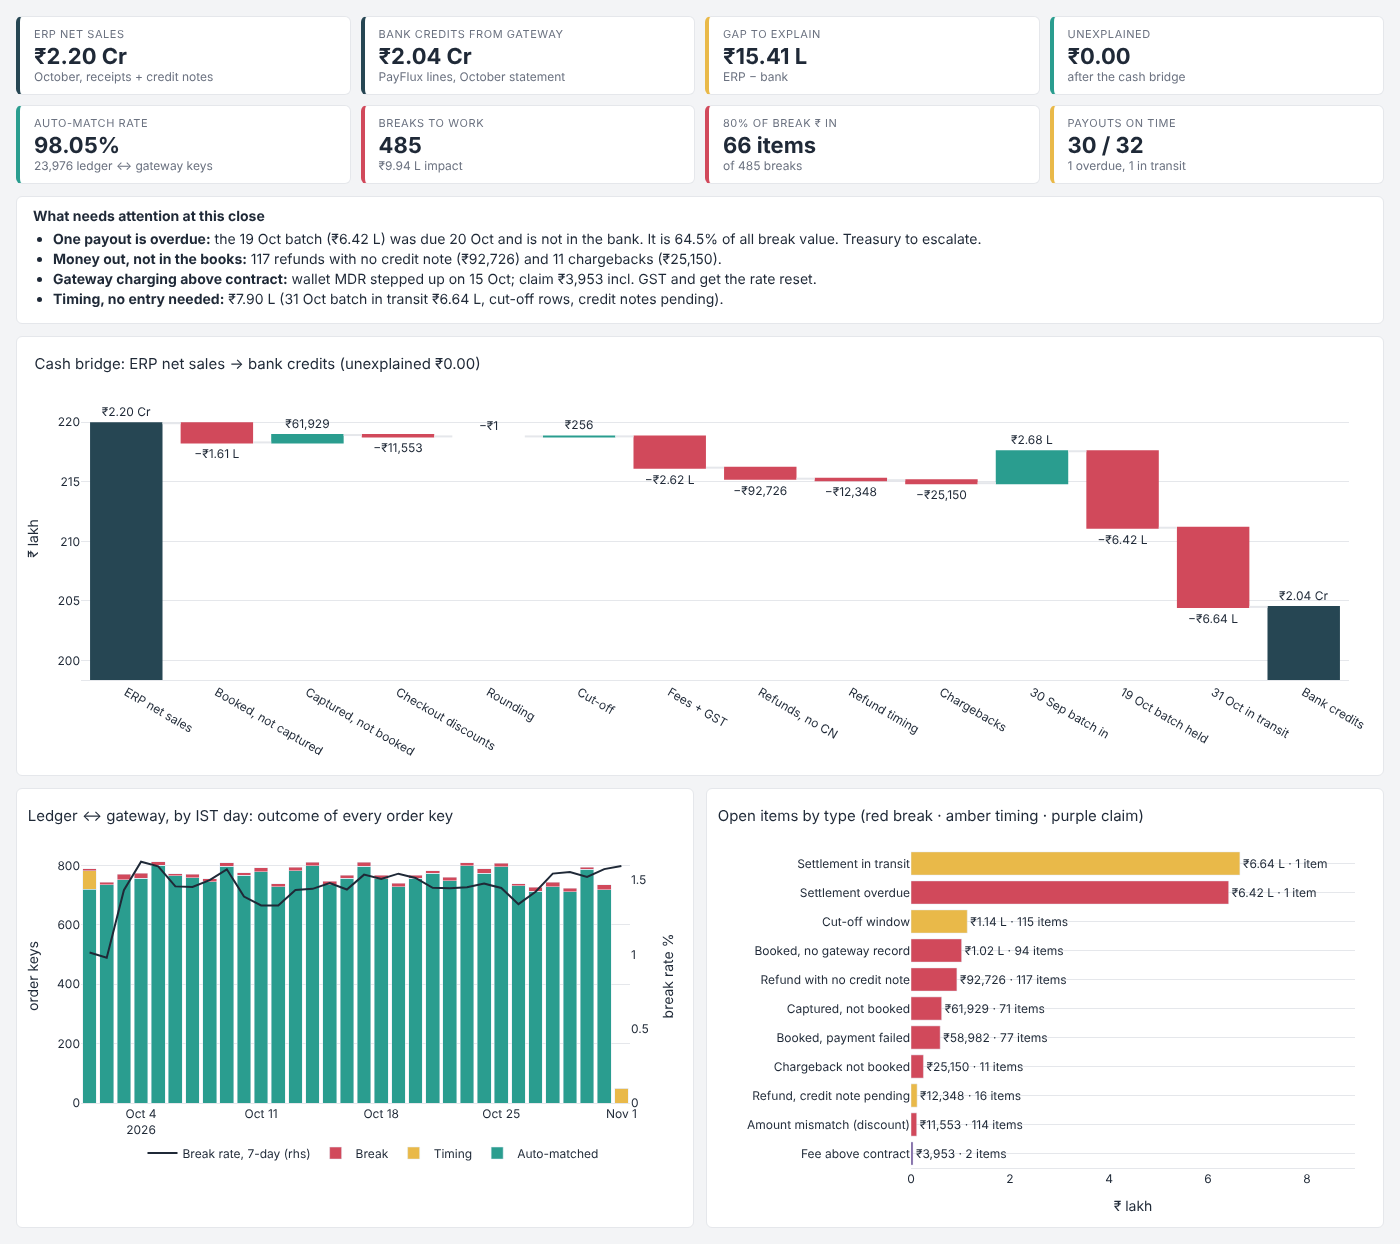

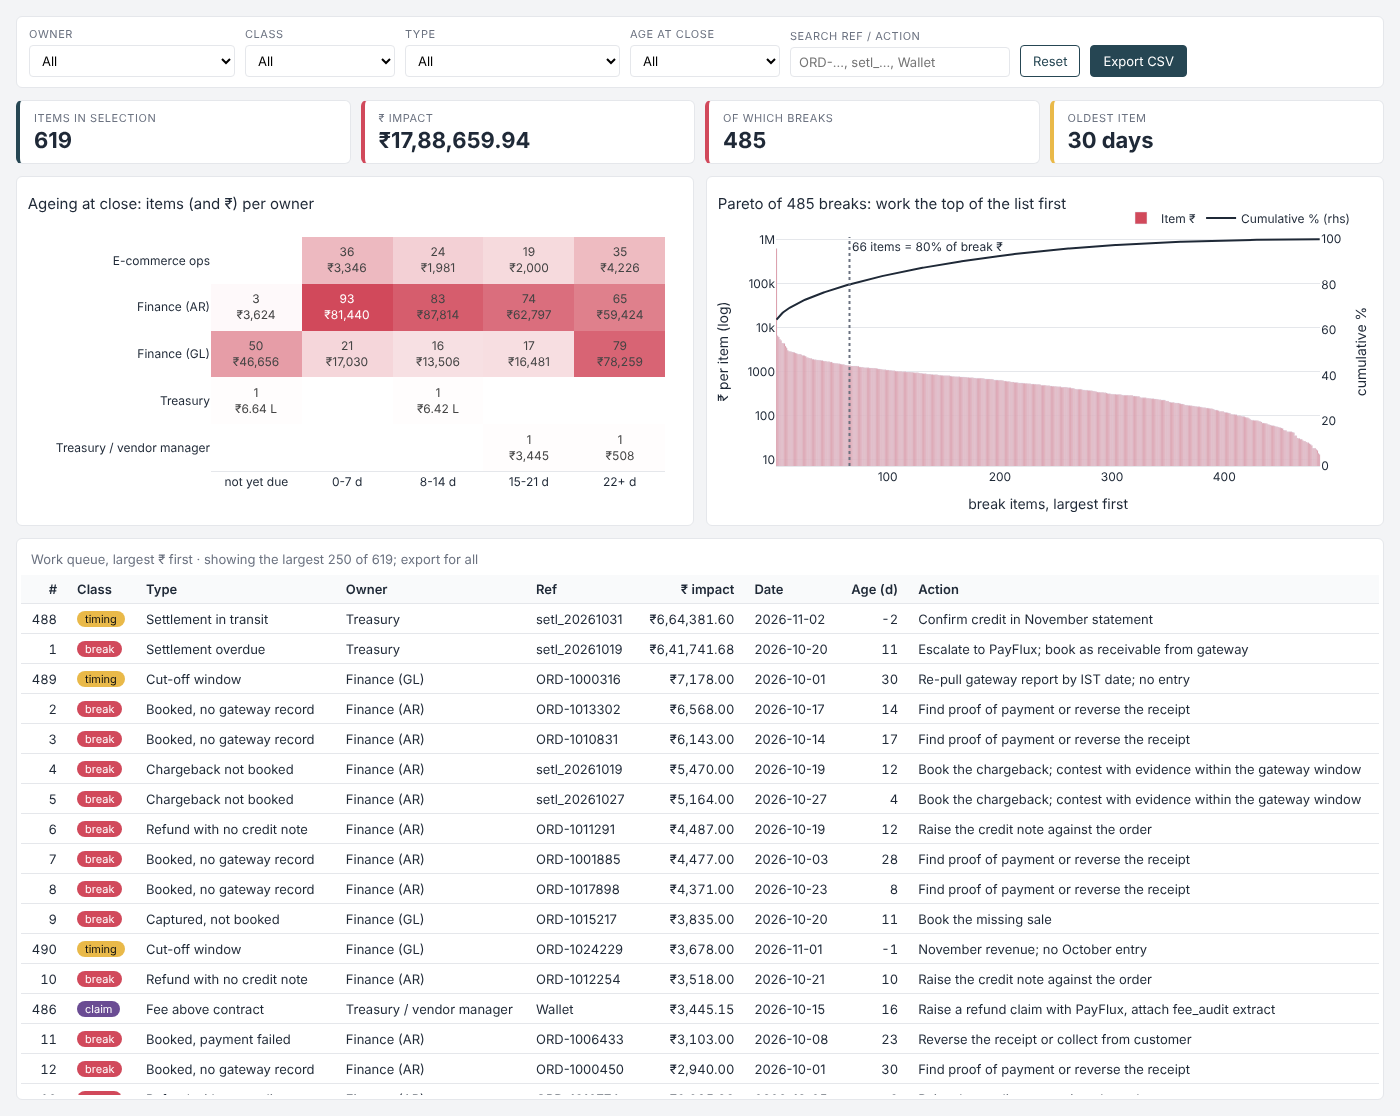

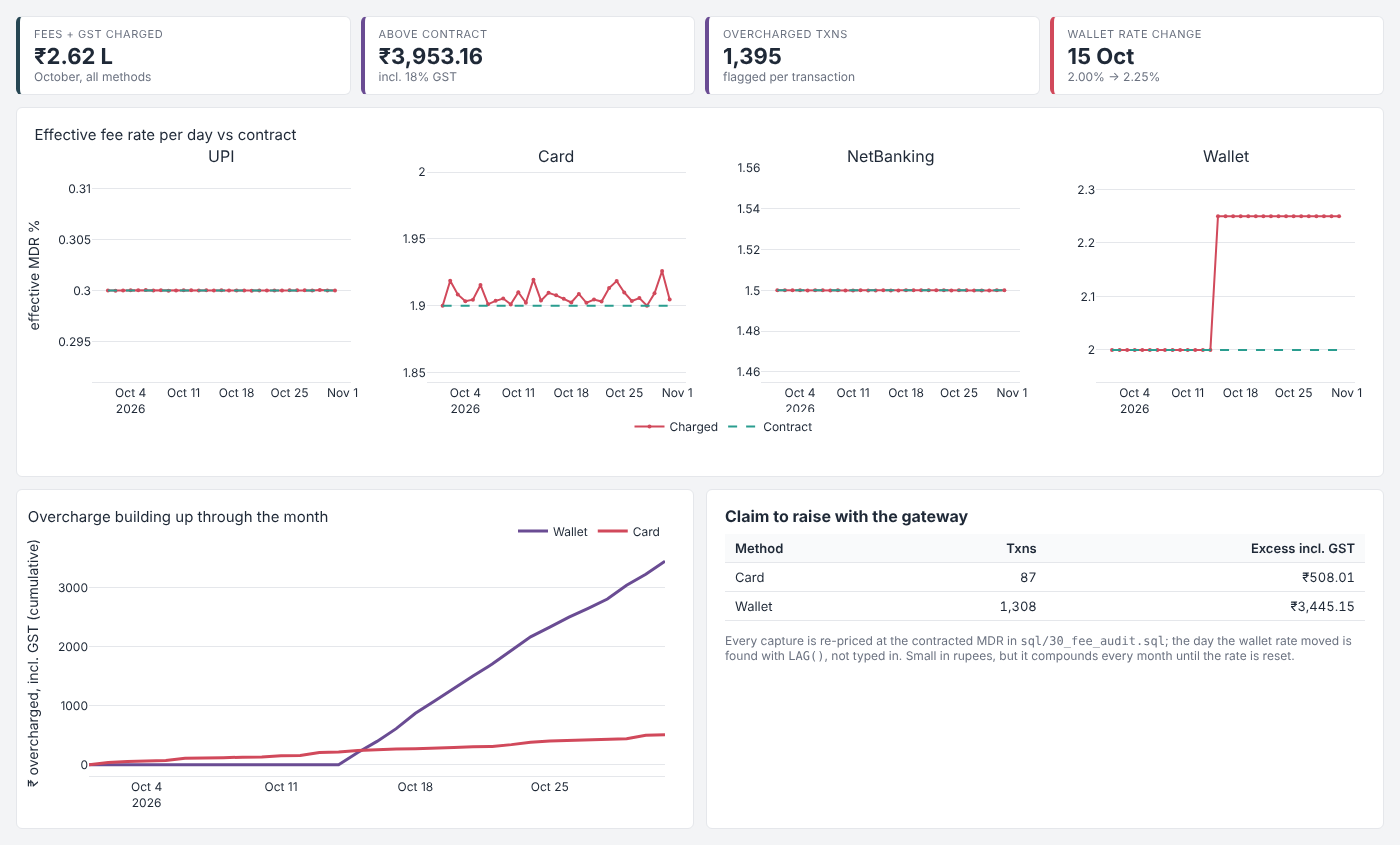

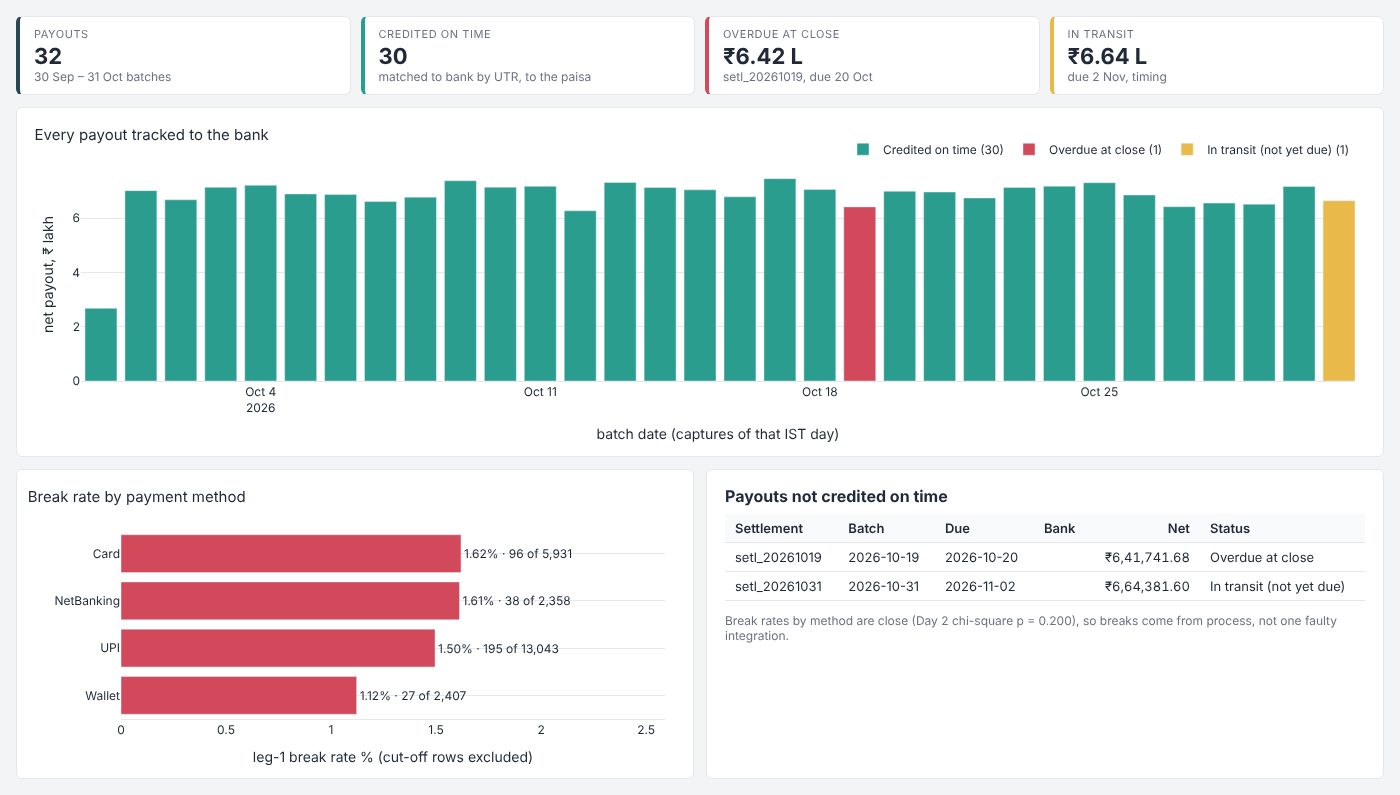

In [11]:
for name in ["11_dashboard_overview", "12_dashboard_exceptions", "13_dashboard_fees", "14_dashboard_settlements"]:
    p = ROOT / "images" / f"{name}.png"
    if p.exists():
        display(Image(filename=str(p), width=900))

## Takeaways

- The dashboard answers the controller's four questions on one page each, and every card is tied back to the engine before the page is written.
- **Exceptions page = the work queue.** Filter to an owner and the largest items come first; export goes straight into the team's tracker.
- **Ageing is the new insight today**: nearly half the breaks were already over two weeks old at close, which makes the case for running the engine daily, not monthly. Day 6 sizes that in ₹.